=== 1. Missing Values Report ===


,Missing Count,Missing Percentage (%),Data Type
SEQN,0,0.0,float64
survey_cycle,0,0.0,str
RIDAGEYR,0,0.0,float64
RIAGENDR,0,0.0,float64
RIDRETH3,0,0.0,float64
WTSAF2YR,0,0.0,float64
valid_days_count,0,0.0,int64
mean_daily_wear_mins,0,0.0,float64
metabolic_syndrome_target,0,0.0,int64
smoking_status,0,0.0,str



=== 2. Numerical Summary Statistics ===


,RIDAGEYR,valid_days_count,mean_daily_wear_mins,WTSAF2YR
count,4604.00,4604.00,4604.00,4604.00
mean,49.37,8.90,2751549.28,88499.60
std,17.55,0.62,709431.23,81918.58
min,20.00,3.00,422512.80,0.00
25%,34.00,9.00,2314851.31,36430.13
50%,49.00,9.00,2632395.44,60602.57
75%,63.00,9.00,3016278.00,109371.09
max,80.00,9.00,6104283.89,521033.37


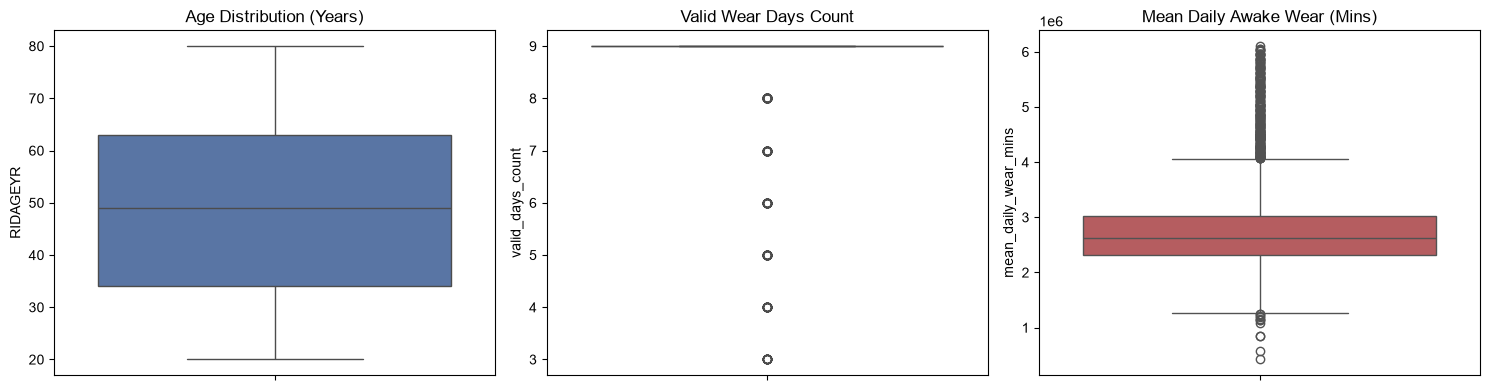

In [1]:
import os
import sys
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Resolve project root
current_dir = os.path.abspath("")
project_root = os.path.dirname(current_dir) if os.path.basename(current_dir) == "notebooks" else current_dir
processed_dir = os.path.join(project_root, "data", "processed")
figures_dir = os.path.join(project_root, "reports", "figures")
os.makedirs(figures_dir, exist_ok=True)

# Load clean cohort dataset (4,604 participants)
clean_df = pd.read_parquet(os.path.join(processed_dir, "clean_cohort_base.parquet"))

# ---------------------------------------------------------
# M1-06: Missing Values & Covariate Outlier Inspection
# ---------------------------------------------------------
print("=== 1. Missing Values Report ===")
missing_summary = pd.DataFrame({
    "Missing Count": clean_df.isnull().sum(),
    "Missing Percentage (%)": (clean_df.isnull().mean() * 100).round(2),
    "Data Type": clean_df.dtypes
})
display(missing_summary)

print("\n=== 2. Numerical Summary Statistics ===")
numeric_cols = ["RIDAGEYR", "valid_days_count", "mean_daily_wear_mins", "WTSAF2YR"]
display(clean_df[numeric_cols].describe().round(2))

# Box plots for outlier inspection
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
sns.set_style("whitegrid")

sns.boxplot(y=clean_df["RIDAGEYR"], ax=axes[0], color="#4C72B0")
axes[0].set_title("Age Distribution (Years)")

sns.boxplot(y=clean_df["valid_days_count"], ax=axes[1], color="#55A868")
axes[1].set_title("Valid Wear Days Count")

sns.boxplot(y=clean_df["mean_daily_wear_mins"], ax=axes[2], color="#C44E52")
axes[2].set_title("Mean Daily Awake Wear (Mins)")

plt.tight_layout()
plt.savefig(os.path.join(figures_dir, "m1_06_covariate_boxplots.png"), dpi=300)
plt.show()

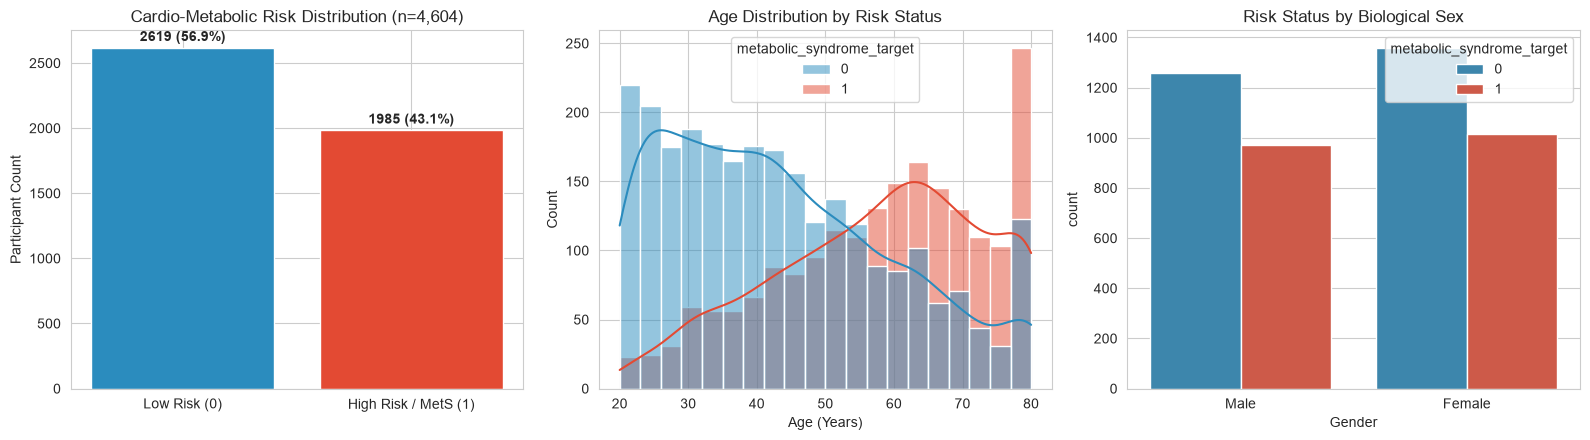

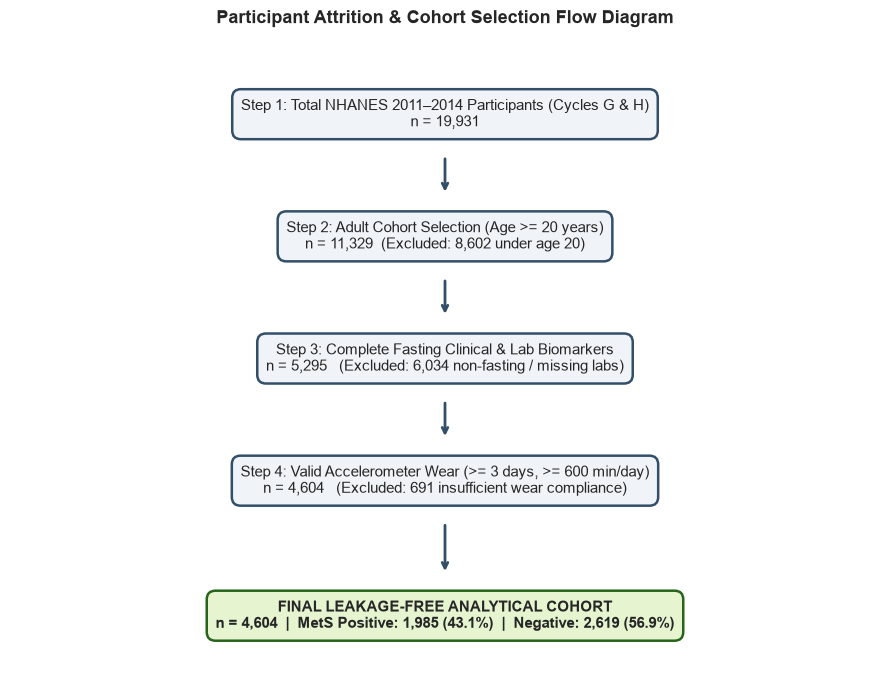

All EDA & Attrition figures saved to: e:\machine learning\project\mechine-learning-\reports\figures


In [3]:
# ---------------------------------------------------------
# M1-08: Exploratory Data Analysis (EDA) Plots
# ---------------------------------------------------------
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

# Plot 1: Target Class Balance
target_counts = clean_df["metabolic_syndrome_target"].value_counts()
axes[0].bar(["Low Risk (0)", "High Risk / MetS (1)"], target_counts.values, color=["#2b8cbe", "#e34a33"])
axes[0].set_title("Cardio-Metabolic Risk Distribution (n=4,604)")
axes[0].set_ylabel("Participant Count")
for i, v in enumerate(target_counts.values):
    axes[0].text(i, v + 50, f"{v} ({v/len(clean_df)*100:.1f}%)", ha="center", fontweight="bold")

# Plot 2: Age Distribution by Metabolic Syndrome Target
sns.histplot(data=clean_df, x="RIDAGEYR", hue="metabolic_syndrome_target", bins=20, kde=True, ax=axes[1], palette=["#2b8cbe", "#e34a33"])
axes[1].set_title("Age Distribution by Risk Status")
axes[1].set_xlabel("Age (Years)")

# Plot 3: Risk Prevalence by Gender (1=Male, 2=Female)
gender_df = clean_df.copy()
gender_df["Gender"] = gender_df["RIAGENDR"].map({1.0: "Male", 2.0: "Female"})
sns.countplot(data=gender_df, x="Gender", hue="metabolic_syndrome_target", ax=axes[2], palette=["#2b8cbe", "#e34a33"])
axes[2].set_title("Risk Status by Biological Sex")

plt.tight_layout()
plt.savefig(os.path.join(figures_dir, "m1_08_eda_distributions.png"), dpi=300)
plt.show()

# ---------------------------------------------------------
# M1-08: Participant Attrition Flow Diagram
# ---------------------------------------------------------
fig, ax = plt.subplots(figsize=(9, 7))
ax.axis("off")

steps = [
    ("Step 1: Total NHANES 2011–2014 Participants (Cycles G & H)", "n = 19,931"),
    ("Step 2: Adult Cohort Selection (Age >= 20 years)", "n = 11,329  (Excluded: 8,602 under age 20)"),
    ("Step 3: Complete Fasting Clinical & Lab Biomarkers", "n = 5,295   (Excluded: 6,034 non-fasting / missing labs)"),
    ("Step 4: Valid Accelerometer Wear (>= 3 days, >= 600 min/day)", "n = 4,604   (Excluded: 691 insufficient wear compliance)"),
    ("FINAL LEAKAGE-FREE ANALYTICAL COHORT", "n = 4,604  |  MetS Positive: 1,985 (43.1%)  |  Negative: 2,619 (56.9%)")
]

y_positions = [0.88, 0.69, 0.50, 0.31, 0.10]

for idx, ((title, subtitle), y) in enumerate(zip(steps, y_positions)):
    box_color = "#e6f5d0" if idx == len(steps) - 1 else "#f0f4f8"
    edge_color = "#276419" if idx == len(steps) - 1 else "#334e68"
    
    ax.text(
        0.5, y, f"{title}\n{subtitle}",
        ha="center", va="center", fontsize=10.5, fontweight="bold" if idx == len(steps)-1 else "normal",
        bbox=dict(boxstyle="round,pad=0.6", facecolor=box_color, edgecolor=edge_color, linewidth=1.8)
    )
    
    if idx < len(steps) - 1:
        ax.annotate(
            "", xy=(0.5, y_positions[idx+1] + 0.065), xytext=(0.5, y - 0.065),
            arrowprops=dict(arrowstyle="->", lw=2, color="#334e68")
        )

plt.title("Participant Attrition & Cohort Selection Flow Diagram", fontsize=13, fontweight="bold", pad=10)
plt.tight_layout()
plt.savefig(os.path.join(figures_dir, "m1_08_attrition_flow_diagram.png"), dpi=300)
plt.show()
print(f"All EDA & Attrition figures saved to: {figures_dir}")